In [4]:
# change in loaddata.py to "augmented_maps2d/gaussian_alpha_005"
import os
import sys
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Add the parent directory to the path so we can import Danial/Alen's code
sys.path.append(os.path.abspath(".."))

from train_single import get_model_class
from torch import nn

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


In [5]:
from fetch import Get2dMapTestData, Get2dMapTrainFold
from torch.utils.data import TensorDataset, DataLoader
import math

def get_test_data_scaled(level, data_root):
    """Loads the test data and scales it using the training set's mean/std."""
    # 1. Get the mean/std from the training folds
    X_train_list = []
    for fold in range(1, 5): 
        X, _ = Get2dMapTrainFold(level, fold, root=data_root)
        X = np.log10(np.maximum(np.array(X, dtype=np.float32), 1e-5))
        X_train_list.append(X)
        
    X_train_concat = np.concatenate(X_train_list, axis=0)
    train_mean = np.mean(X_train_concat)
    train_std = np.std(X_train_concat)
    
    # 2. Load the actual Test Data
    print(f"Loading Test Data from '{data_root}'...")
    X_test, Y_test = Get2dMapTestData(level, root=data_root)
    X_test = np.array(X_test, dtype=np.float32)
    Y_test = np.array(Y_test, dtype=np.float32)
    
    X_test = np.log10(np.maximum(X_test, 1e-5))
    X_test = np.expand_dims(X_test, axis=1) # Add channel dim
    
    # 3. Apply the training scale
    X_test = (X_test - train_mean) / train_std
    return X_test, Y_test


def evaluate_exact_model(weights_path, level, data_root):
    """Evaluates an exact .pth file on the test set."""
    
    if not os.path.exists(weights_path):
        raise FileNotFoundError(f"Missing weights: {weights_path}")
        
    # Extract model name from the path (e.g. "aug01_model_10_5_level3.pth" -> "model_10_5")
    # We do this just so we know which architecture to load
    filename = os.path.basename(weights_path)
    base_name = filename.replace("aug01_", "").replace("aug05_", "").replace(f"_level{level}.pth", "")
    
    # Load Test Data
    X_test, Y_test = get_test_data_scaled(level, data_root)
    
    test_dataset = TensorDataset(
        torch.tensor(X_test, dtype=torch.float32), 
        torch.tensor(Y_test, dtype=torch.float32)
    )
    test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
    
    # Load Model
    model_class = get_model_class(base_name)
    model = model_class().to(device)
    model.load_state_dict(torch.load(weights_path, map_location=device, weights_only=True))
    model.eval()
    
    total_mae_omega_m = 0.0
    total_mae_sigma_8 = 0.0
    total_sqerr_omega_m = 0.0
    total_sqerr_sigma_8 = 0.0
    num_samples = 0
    
    with torch.no_grad():
        for bx, by in test_loader:
            bx, by = bx.to(device), by.to(device)
            predictions = model(bx)
            
            batch_size = bx.size(0)
            num_samples += batch_size
            
            total_mae_omega_m += torch.sum(torch.abs(predictions[:, 0] - by[:, 0])).item()
            total_mae_sigma_8 += torch.sum(torch.abs(predictions[:, 1] - by[:, 1])).item()
            total_sqerr_omega_m += torch.sum((predictions[:, 0] - by[:, 0])**2).item()
            total_sqerr_sigma_8 += torch.sum((predictions[:, 1] - by[:, 1])**2).item()

    return {
        "Omega_m MAE": total_mae_omega_m / num_samples,
        "Sigma_8 MAE": total_mae_sigma_8 / num_samples,
        "Omega_m RMSE": math.sqrt(total_sqerr_omega_m / num_samples),
        "Sigma_8 RMSE": math.sqrt(total_sqerr_sigma_8 / num_samples)
    }

In [6]:
LEVEL = 3


# GROUP 1 (Depths 4-10)
g1_1pct_paths = [
    "aug_checkpoints/001_4-10/checkpoints/level3/aug01_model_8_4_level3.pth",
    "aug_checkpoints/001_4-10/checkpoints/level3/aug01_model_8_5_level3.pth",
    "aug_checkpoints/001_4-10/checkpoints/level3/aug01_model_10_2_level3.pth",
    "aug_checkpoints/001_4-10/checkpoints/level3/aug01_model_10_4_level3.pth",
    "aug_checkpoints/001_4-10/checkpoints/level3/aug01_model_10_5_level3.pth"
]

g1_5pct_paths = [
    "aug_checkpoints/005_4-10/checkpoints/level3/aug05_model_8_2_level3.pth",
    "aug_checkpoints/005_4-10/checkpoints/level3/aug05_model_8_4_level3.pth",
    "aug_checkpoints/005_4-10/checkpoints/level3/aug05_model_8_5_level3.pth",
    "aug_checkpoints/005_4-10/checkpoints/level3/aug05_model_10_4_level3.pth",
    "aug_checkpoints/005_4-10/checkpoints/level3/aug05_model_10_5_level3.pth"
]

# GROUP 2 (Depths 12-16)
g2_1pct_paths = [
    "aug_checkpoints/001_12-16/checkpoints/level3/aug01_model_16_1_level3.pth",
    "aug_checkpoints/001_12-16/checkpoints/level3/aug01_model_16_2_level3.pth",
    "aug_checkpoints/001_12-16/checkpoints/level3/aug01_model_16_3_level3.pth",
    "aug_checkpoints/001_12-16/checkpoints/level3/aug01_model_16_4_level3.pth",
    "aug_checkpoints/001_12-16/checkpoints/level3/aug01_model_16_5_level3.pth"
]

g2_5pct_paths = [
    "aug_checkpoints/005_12-16/checkpoints/level3/aug05_model_12_2_level3.pth",
    "aug_checkpoints/005_12-16/checkpoints/level3/aug05_model_14_2_level3.pth",
    "aug_checkpoints/005_12-16/checkpoints/level3/aug05_model_16_1_level3.pth",
    "aug_checkpoints/005_12-16/checkpoints/level3/aug05_model_16_2_level3.pth",
    "aug_checkpoints/005_12-16/checkpoints/level3/aug05_model_16_7_level3.pth"
]

# ========================================

def evaluate_list(path_list, level, data_root):
    """Evaluates a hardcoded list of paths and returns the average metrics."""
    group_metrics = {"Omega_m MAE": 0, "Sigma_8 MAE": 0, "Omega_m RMSE": 0, "Sigma_8 RMSE": 0}
    valid_models = 0
    
    for path in path_list:
        try:
            metrics = evaluate_exact_model(path, level, data_root)
            for k in group_metrics:
                group_metrics[k] += metrics[k]
            valid_models += 1
        except Exception as e:
            print(f"FAILED on {path}: {e}")
            
    if valid_models > 0:
        for k in group_metrics:
            group_metrics[k] /= valid_models
    return group_metrics

# --- RUN EVALUATION ---
print("\n--- Evaluating Group 1 ---")
g1_1pct_results = evaluate_list(g1_1pct_paths, LEVEL, "augmented_maps2d/gaussian_alpha_001")
g1_5pct_results = evaluate_list(g1_5pct_paths, LEVEL, "augmented_maps2d/gaussian_alpha_005")

print("\n--- Evaluating Group 2 ---")
g2_1pct_results = evaluate_list(g2_1pct_paths, LEVEL, "augmented_maps2d/gaussian_alpha_001")
g2_5pct_results = evaluate_list(g2_5pct_paths, LEVEL, "augmented_maps2d/gaussian_alpha_005")

df_g1 = pd.DataFrame({"1% Noise": g1_1pct_results, "5% Noise": g1_5pct_results}).T
df_g2 = pd.DataFrame({"1% Noise": g2_1pct_results, "5% Noise": g2_5pct_results}).T

display("Group 1 (Depths 4-10) Test Set Averages:", df_g1)
display("Group 2 (Depths 12-16) Test Set Averages:", df_g2)


--- Evaluating Group 1 ---
Loading Test Data from 'augmented_maps2d/gaussian_alpha_001'...
Loading Test Data from 'augmented_maps2d/gaussian_alpha_001'...
Loading Test Data from 'augmented_maps2d/gaussian_alpha_001'...
Loading Test Data from 'augmented_maps2d/gaussian_alpha_001'...
Loading Test Data from 'augmented_maps2d/gaussian_alpha_001'...
Loading Test Data from 'augmented_maps2d/gaussian_alpha_005'...
Loading Test Data from 'augmented_maps2d/gaussian_alpha_005'...
Loading Test Data from 'augmented_maps2d/gaussian_alpha_005'...
Loading Test Data from 'augmented_maps2d/gaussian_alpha_005'...
Loading Test Data from 'augmented_maps2d/gaussian_alpha_005'...

--- Evaluating Group 2 ---
Loading Test Data from 'augmented_maps2d/gaussian_alpha_001'...
Loading Test Data from 'augmented_maps2d/gaussian_alpha_001'...
Loading Test Data from 'augmented_maps2d/gaussian_alpha_001'...
Loading Test Data from 'augmented_maps2d/gaussian_alpha_001'...
Loading Test Data from 'augmented_maps2d/gaussia

'Group 1 (Depths 4-10) Test Set Averages:'

,Omega_m MAE,Sigma_8 MAE,Omega_m RMSE,Sigma_8 RMSE
1% Noise,0.048091,0.060267,0.060635,0.075177
5% Noise,0.050657,0.063962,0.063642,0.080117


'Group 2 (Depths 12-16) Test Set Averages:'

,Omega_m MAE,Sigma_8 MAE,Omega_m RMSE,Sigma_8 RMSE
1% Noise,0.040007,0.053806,0.051386,0.068414
5% Noise,0.048518,0.063897,0.061519,0.080337


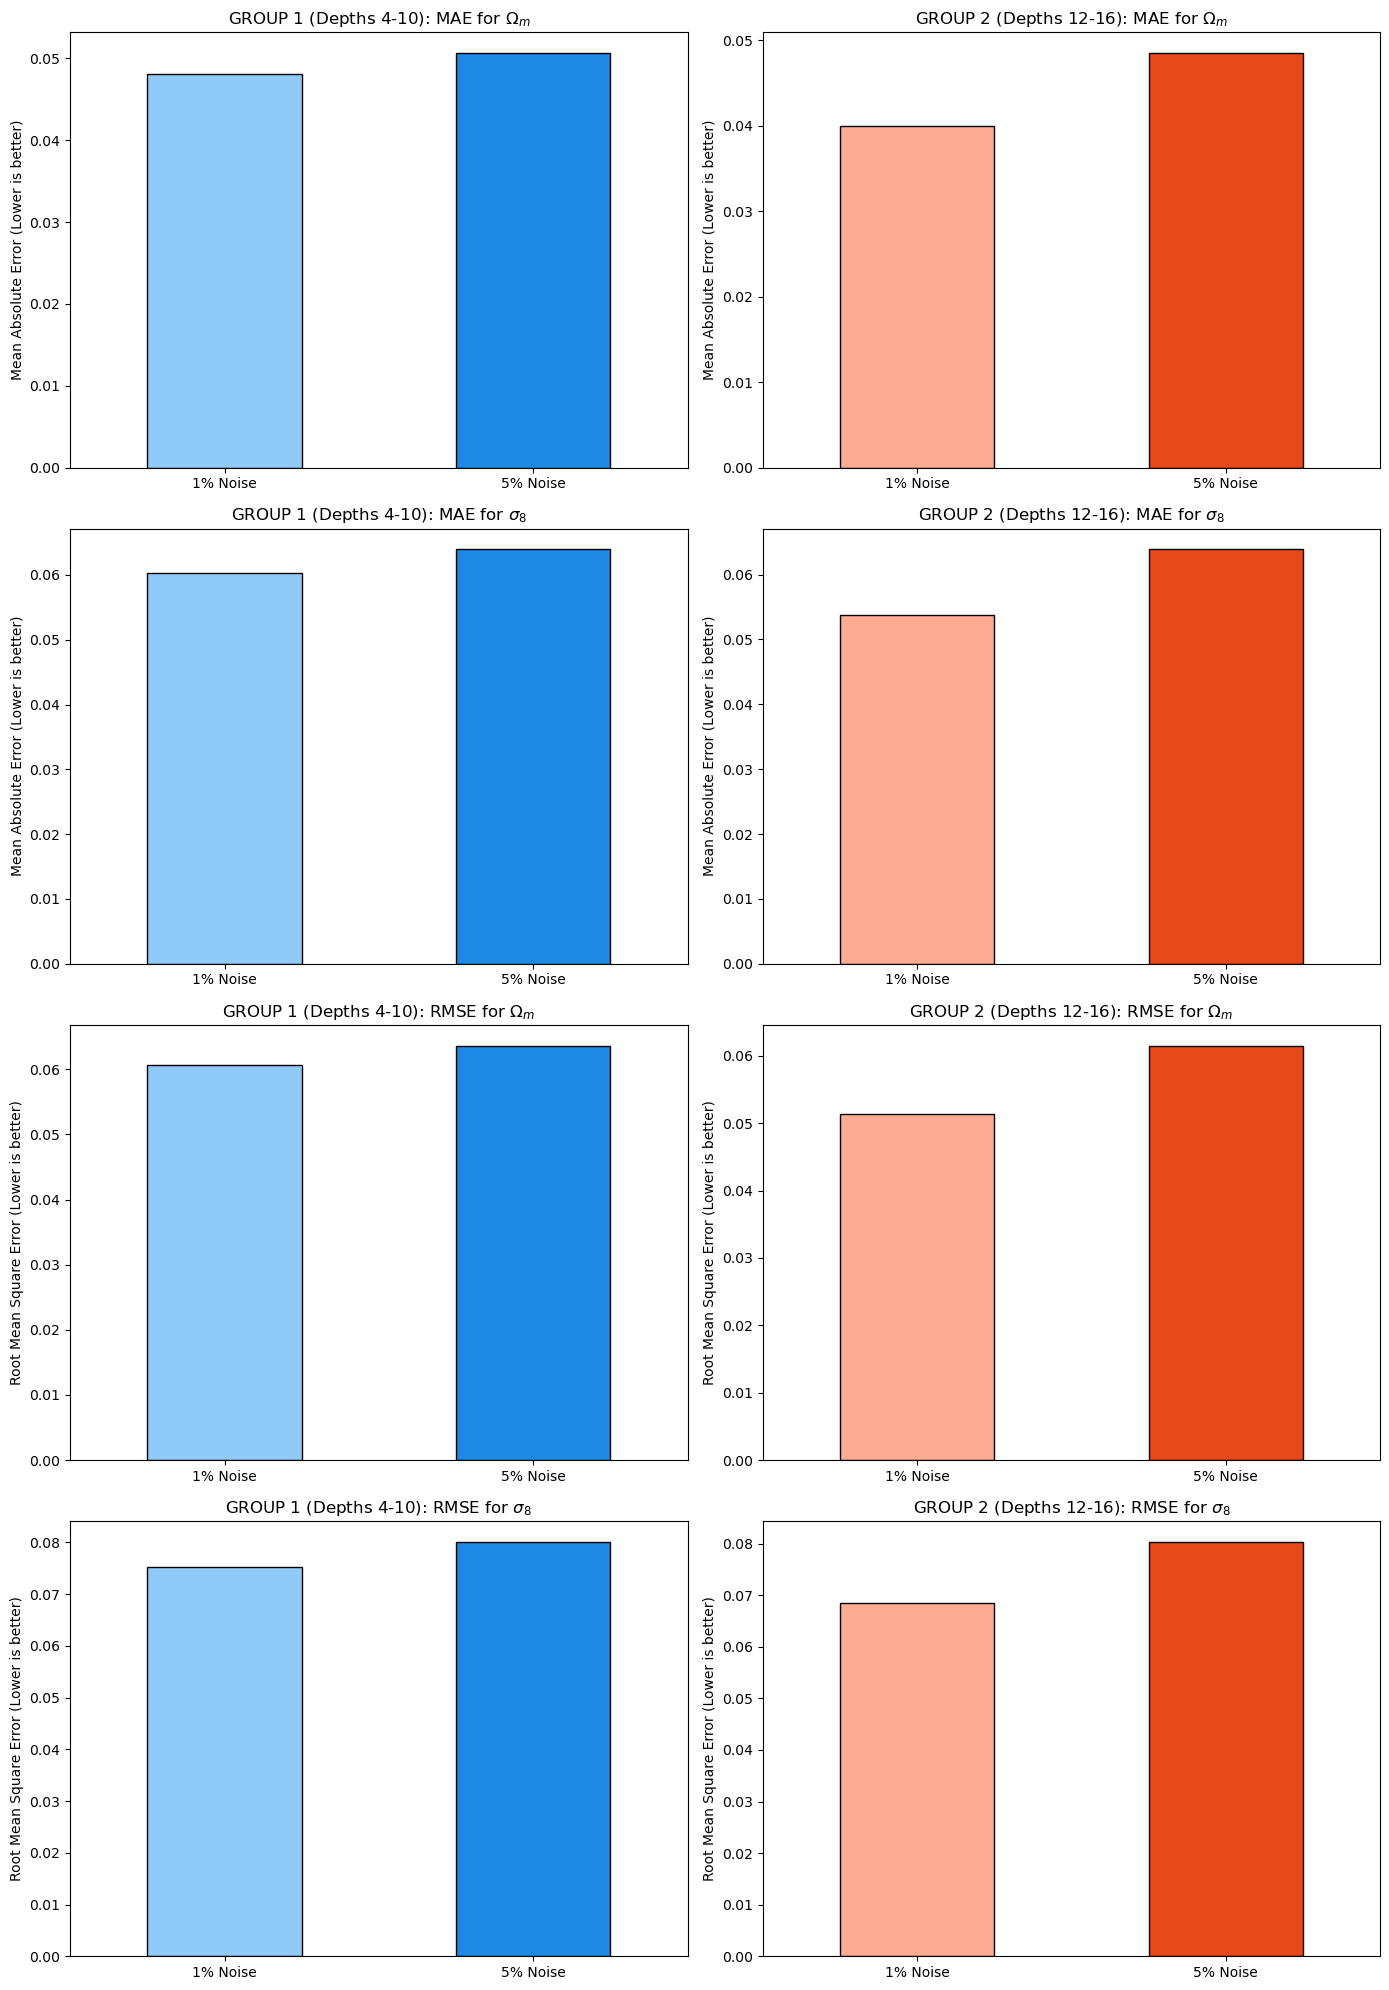

In [8]:
# Create a 4x2 grid. 
# Rows: Omega_m MAE, Sigma_8 MAE, Omega_m RMSE, Sigma_8 RMSE
# Cols: Group 1 vs Group 2
fig, axes = plt.subplots(4, 2, figsize=(14, 20))

metrics_to_plot = [
    ('Omega_m MAE', 'MAE for $\Omega_m$', 'Mean Absolute Error'),
    ('Sigma_8 MAE', 'MAE for $\sigma_8$', 'Mean Absolute Error'),
    ('Omega_m RMSE', 'RMSE for $\Omega_m$', 'Root Mean Square Error'),
    ('Sigma_8 RMSE', 'RMSE for $\sigma_8$', 'Root Mean Square Error')
]

for row, (metric, title, y_label) in enumerate(metrics_to_plot):
    # --- Plot Group 1 (Left Column) ---
    # We use light blue for 1% Noise, and dark blue for 5% Noise
    df_g1[metric].plot(
        kind='bar', 
        ax=axes[row, 0], 
        color=['#90caf9', '#1e88e5'], 
        edgecolor='black'
    )
    axes[row, 0].set_title(f"GROUP 1 (Depths 4-10): {title}")
    axes[row, 0].set_ylabel(f"{y_label} (Lower is better)")
    axes[row, 0].tick_params(axis='x', rotation=0)
    
    # --- Plot Group 2 (Right Column) ---
    # We use light orange for 1% Noise, and dark orange for 5% Noise
    df_g2[metric].plot(
        kind='bar', 
        ax=axes[row, 1], 
        color=['#ffab91', '#e64a19'], 
        edgecolor='black'
    )
    axes[row, 1].set_title(f"GROUP 2 (Depths 12-16): {title}")
    axes[row, 1].set_ylabel(f"{y_label} (Lower is better)")
    axes[row, 1].tick_params(axis='x', rotation=0)

plt.tight_layout()

# Save the comprehensive chart
plt.savefig("Group_Comparison_Noise_Complete.png", dpi=300, bbox_inches='tight')
plt.show()